# OULAD Controlled Ablation



**Contents:**
1. Introduction to OULAD
2. EDA
3. Setup (variable-family
catalogue)
4. Feature groups
5. Balancing methods


In [ ]:
import os, sys, time, pickle, warnings
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn, imblearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
assert sklearn.__version__.startswith("1.7"), f"sklearn degraded: {sklearn.__version__}"

SEED = 42
CORTE = 30
RAW, PROC, RES, FIGS = "data/raw/", "data/processed/", "results/", "00zfigs_eng/"
os.makedirs(RES, exist_ok=True); os.makedirs(FIGS, exist_ok=True)
NA = ["?"]
KEY = ["id_student", "code_module", "code_presentation"]

print(f"python {sys.version.split()[0]} | sklearn {sklearn.__version__} | "
      f"imblearn {imblearn.__version__} | pandas {pd.__version__} | seed {SEED}")


python 3.13.5 | sklearn 1.7.2 | imblearn 0.14.2 | pandas 2.3.3 | seed 42


## 1. Introduction: Thhe OULAD dataset

The **Open University Learning Analytics Dataset** (OULAD; Kuzilek, Hlosta &
Zdrahal, 2017, *"Open University Learning Analytics dataset,"* Scientific Data
4:170171) is a public, CC-BY 4.0 dataset combining student demographics,
registration records, assessment scores, and Virtual Learning Environment (VLE)
clickstream logs across 22 module-presentations delivered in 2013-2014 — a rare
combination of administrative and behavioural data that makes it a standard
benchmark for dropout/attrition prediction.

OULAD is **already inside our review corpus**: it is reused by three included
studies, among them Adnan et al. (2021, *IEEE Access*, Random Forest, n=32,593).


In [ ]:
si  = pd.read_csv(RAW + "studentInfo.csv",         na_values=NA)
sr  = pd.read_csv(RAW + "studentRegistration.csv", na_values=NA)
sa  = pd.read_csv(RAW + "studentAssessment.csv",   na_values=NA)
ass = pd.read_csv(RAW + "assessments.csv",         na_values=NA)
vle = pd.read_csv(RAW + "vle.csv",                 na_values=NA)
cur = pd.read_csv(RAW + "courses.csv",             na_values=NA)
n_vle = sum(len(c) for c in pd.read_csv(RAW + "studentVle.csv", usecols=["date"],
                                        chunksize=2_000_000))

print("Tables and row counts (read directly from data/raw/):")
for name, d in [("studentInfo", si), ("studentRegistration", sr),
                ("studentAssessment", sa), ("assessments", ass),
                ("vle", vle), ("courses", cur)]:
    print(f"  {name:22} {len(d):>10,} rows, {d.shape[1]} columns")
print(f"  {'studentVle':22} {n_vle:>10,} rows (read in chunks)")
print()
print(f"module-presentations : {si.groupby(['code_module','code_presentation']).ngroups}")
print(f"unique students      : {si.id_student.nunique():,}")
print(f"course length range  : {cur.module_presentation_length.min()}-"
      f"{cur.module_presentation_length.max()} days")


Tables and row counts (read directly from data/raw/):
  studentInfo                32,593 rows, 12 columns
  studentRegistration        32,593 rows, 5 columns
  studentAssessment         173,912 rows, 5 columns
  assessments                   206 rows, 6 columns
  vle                         6,364 rows, 6 columns
  courses                        22 rows, 3 columns
  studentVle             10,655,280 rows (read in chunks)

module-presentations : 22
unique students      : 28,785
course length range  : 234-269 days


## 2. Exploratory Data Analysis

Three checks that condition the experimental design (verified here, not assumed):
whether the analysis unit is the student or the student-presentation (drives the
cross-validation protocol), whether formative assessments exist before the day-30
cutoff, and whether OULAD records literal assignment retries. We also inspect the
raw outcome distribution and the withdrawal-date/cutoff relationship before fixing
the cohort exclusions.


                  n   pct
final_result             
Pass          12361  37.9
Withdrawn     10156  31.2
Fail           7052  21.6
Distinction    3024   9.3

rows belonging to a student who appears in >1 presentation: 7,346  -> cross-validation must be GROUPED by id_student
module-presentations with >=1 assessment before day 30: 16 of 22
duplicated (id_assessment, id_student) rows in studentAssessment: 0  -> OULAD records no literal assignment retries (see Section 3)


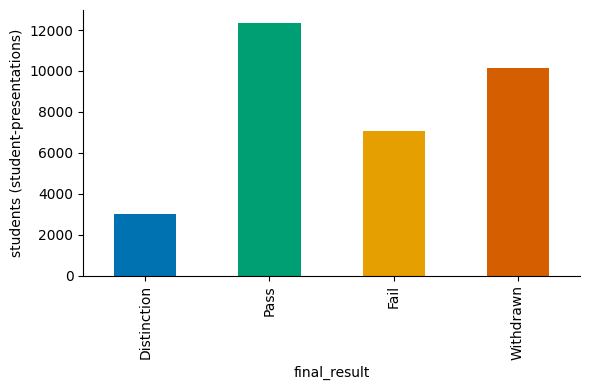

In [ ]:
print(si.final_result.value_counts().rename("n").to_frame()
      .assign(pct=lambda d: (d.n / len(si) * 100).round(1)))

dup_students = si.id_student.duplicated(keep=False).sum()
print(f"\nrows belonging to a student who appears in >1 presentation: {dup_students:,}"
      "  -> cross-validation must be GROUPED by id_student")

tmacma = ass[ass.assessment_type.isin(["TMA", "CMA"])]
n_pp_with_eval = tmacma[tmacma.date < CORTE].groupby(
    ["code_module", "code_presentation"]).ngroups
n_pp_total = ass.groupby(["code_module", "code_presentation"]).ngroups
print(f"module-presentations with >=1 assessment before day {CORTE}: "
      f"{n_pp_with_eval} of {n_pp_total}")

dup_retries = sa.duplicated(["id_assessment", "id_student"]).sum()
print(f"duplicated (id_assessment, id_student) rows in studentAssessment: {dup_retries}"
      "  -> OULAD records no literal assignment retries (see Section 3)")

fig, ax = plt.subplots(figsize=(6, 4))
si.final_result.value_counts().reindex(
    ["Distinction", "Pass", "Fail", "Withdrawn"]).plot.bar(
    ax=ax, color=["#0072B2", "#009E73", "#E69F00", "#D55E00"])
ax.set_ylabel("students (student-presentations)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS + "FINAL_00_final_result.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
m = si.merge(sr, on=KEY, how="left", validate="1:1")
w = m.loc[m.final_result == "Withdrawn", "date_unregistration"]
before_start = int((w < 0).sum())
before_cut   = int(((w >= 0) & (w < CORTE)).sum())
after_cut    = int((w >= CORTE).sum())
print(f"Withdrawn = {len(w):,} | left before start: {before_start:,} | "
      f"left in [0,{CORTE}): {before_cut:,} (outcome already happened) | "
      f"left >= {CORTE}: {after_cut:,}")
print()
print(f"Target: y=1 iff final_result == 'Withdrawn'. Raw rate = "
      f"{(si.final_result=='Withdrawn').mean():.3f}, matching the ~0.312 reported by "
      "Adnan et al. (2021) for the same dataset (our corpus's own record of that study).")
print(f"Cutoff = day {CORTE} (~12% of a {cur.module_presentation_length.min()}-"
      f"{cur.module_presentation_length.max()} day presentation): early enough for an "
      "intervention to remain actionable. Both exclusions above are applied before "
      "modelling: 'before_start' never truly enrolled, 'before_cut' had already left "
      "when the prediction would be made -- predicting the past is not prediction.")


Withdrawn = 10,156 | left before start: 2,676 | left in [0,30): 2,383 (outcome already happened) | left >= 30: 5,004

Target: y=1 iff final_result == 'Withdrawn'. Raw rate = 0.312, matching the ~0.312 reported by Adnan et al. (2021) for the same dataset (our corpus's own record of that study).
Cutoff = day 30 (~12% of a 234-269 day presentation): early enough for an intervention to remain actionable. Both exclusions above are applied before modelling: 'before_start' never truly enrolled, 'before_cut' had already left when the prediction would be made -- predicting the past is not prediction.


## 3. Setup: How the variable families were catalogued

The 56 features engineered from OULAD for this ablation are grouped into **five
families, assigned manually and pre-registered before running any model**. The assignment follows the review's own variable taxonomy and,
for the behavioural block, the paper's verbatim definition of the foundational tier
of its psychosocial category:

> *"At the foundational level, [this] group relies on behavioral proxies or easily
> collectible indicators... such as... internet navigation time, and local
> persistence measured by the tendency to repeatedly retry assignments."*

OULAD's clickstream **is** internet navigation time, measured rather than
self-reported, so it operationalizes exactly the citations the paper's own taxonomy
already names — but only that foundational, Level-1 tier: OULAD contains no
validated psychometric instrument (no MSLQ subscale, no sense-of-belonging survey),
so the block is labelled **Behavioural-Engagement Proxies (Psychosocial, Level 1)**
throughout, never "Psychosocial" on its own. "Local persistence" has no literal
analogue in OULAD either (Section 2 confirmed zero duplicated assessment attempts);
the closest proxy used here is quiz-click intensity per scheduled assessment.

One pre-registered judgment call worth flagging: `dias_anticipacion_registro`
(days between registration and course start) was assigned to **Institutional**,
not Psychosocial, fixed before seeing any result because it is one of the
strongest OULAD predictors and could otherwise inflate the `ACAD+INST` vs
`ACAD+PSI` contrast either way.


In [ ]:
FAM = {
    "ACAD": [
        "num_intentos_previos", "creditos_estudiados", "educacion_previa_ord",
        "n_evals_programadas", "n_evals_entregadas", "tasa_entrega",
        "nota_media", "nota_min", "nota_ponderada", "alguna_reprobada",
        "alguna_nota_banked", "sin_evaluacion_previa", "sin_entrega_previa",
    ],
    "DEMO": ["genero", "discapacidad", "region", "franja_edad_ord"],
    "SOCIO": ["imd_band_ord", "imd_desconocido"],
    "INST": [
        "code_module", "code_presentation", "anio_presentacion",
        "semestre_presentacion", "duracion_presentacion",
        "dias_anticipacion_registro", "registro_desconocido", "tamano_cohorte",
    ],
    "PSI": [
        "clics_total_pre_corte", "clics_pre_inicio", "dias_activos",
        "clics_medios_por_dia_activo", "clics_max_dia",
        "entropia_compromiso", "cv_clics_diarios", "racha_inactividad_max",
        "dias_desde_ultimo_clic", "dia_primer_clic", "semanas_activas",
        "flag_inactividad_temprana", "pendiente_tendencia_clics",
        "ratio_sem_final_inicial", "sin_actividad_vle",
        "n_sitios_distintos", "n_tipos_actividad", "entropia_tipos_actividad",
        "share_forumng", "share_quiz", "share_oucontent", "share_resource",
        "share_subpage", "share_homepage",
        "intensidad_quiz_por_evaluacion", "adelanto_medio_entrega",
        "n_entregas_tardias", "tasa_entrega_tardia", "n_evals_no_entregadas",
    ],
}
NOMINALES = ["genero", "discapacidad", "region", "code_module",
             "code_presentation", "semestre_presentacion"]
FAM_LABEL = {"ACAD": "Academic", "DEMO": "Demographic", "SOCIO": "Socioeconomic",
             "INST": "Institutional", "PSI": "Behavioural-Engagement (Psychosocial L1)"}

def columnas(bloques):
    return [c for b in bloques for c in FAM[b]]

df = pd.read_parquet(PROC + f"features_cut{CORTE}.parquet")
grupos = df.index.get_level_values("id_student").to_numpy()
y = df["y"].to_numpy()
X = df.drop(columns=["y", "y_recat"]).reset_index(drop=True)

assert sorted(columnas(FAM.keys())) == sorted(X.columns), "family columns don't match parquet"
print(f"Analytic sample: {X.shape[0]:,} rows, {X.shape[1]} features "
      f"(prevalence = {y.mean():.4f})\n")
for fam, cols in FAM.items():
    print(f"  {FAM_LABEL[fam]:42} ({fam:5}) {len(cols):>3} vars")


Analytic sample: 27,526 rows, 56 features (prevalence = 0.1852)

  Academic                                   (ACAD )  13 vars
  Demographic                                (DEMO )   4 vars
  Socioeconomic                              (SOCIO)   2 vars
  Institutional                              (INST )   8 vars
  Behavioural-Engagement (Psychosocial L1)   (PSI  )  29 vars


## 4. Feature groups: Academic Only vs. Academic + Psychosocial

**Fixed classifier: Random Forest** (`n_estimators=200, min_samples_leaf=20,
max_depth=12, max_features='sqrt', random_state=42`).

Cross-validation: **`StratifiedGroupKFold`, 5 folds x 3 repeats, grouped by
`id_student`**. Preprocessing here is intentionally
simplified relative to the full ablation (median imputation + missing indicator
for numeric columns, one-hot encoding for nominal ones): `log1p` and feature
scaling are dropped because Random Forest's splits are invariant to monotonic
transforms and to scaling, so neither can change any result for this classifier.

**Three arms**, balancing fixed to none:

- **Academic Only** (`ACAD`) — the reviewer's baseline arm.
- **Academic + Psychosocial** (`ACAD+PSI`) — the reviewer's second arm; academic
  history + the Level-1 behavioural-engagement block from Section 3.
- **ALL** — all five families accumulated, with no in-fold selection.

Primary metric: **F1-score of the dropout class**. PR-AUC and AUROC are reported
alongside as threshold-independent checks and are never hidden: if a technique
raises F1 without raising PR-AUC, that is reported as exactly that.


In [ ]:
def hacer_preproc(cols):
    nom = [c for c in cols if c in NOMINALES]
    num = [c for c in cols if c not in nom]
    partes = []
    if num:
        partes.append(("num", SimpleImputer(strategy="median", add_indicator=True), num))
    if nom:
        partes.append(("nom", SkPipeline([
            ("imp", SimpleImputer(strategy="constant", fill_value="Desconocido")),
            ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=0.01, sparse_output=False)),
        ]), nom))
    return ColumnTransformer(partes, remainder="drop")


def hacer_clf(cost_sensitive=False):
    return RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, max_depth=12, max_features="sqrt",
        n_jobs=-1, random_state=SEED,
        class_weight="balanced" if cost_sensitive else None)


class SmoteNCAuto:
    """SMOTE-NC that detects one-hot (0/1) columns as categorical at fit time."""

    def __init__(self, random_state=SEED, k_neighbors=5):
        self.random_state, self.k_neighbors = random_state, k_neighbors

    def get_params(self, deep=True):
        return {"random_state": self.random_state, "k_neighbors": self.k_neighbors}

    def set_params(self, **p):
        for k, v in p.items():
            setattr(self, k, v)
        return self

    def fit_resample(self, X, y):
        Xa = np.asarray(X, dtype=float)
        cat = [j for j in range(Xa.shape[1])
               if np.isin(np.unique(Xa[:, j]), [0.0, 1.0]).all()]
        if not cat or len(cat) == Xa.shape[1]:
            return SMOTE(k_neighbors=self.k_neighbors,
                         random_state=self.random_state).fit_resample(Xa, y)
        return SMOTENC(categorical_features=cat, k_neighbors=self.k_neighbors,
                       random_state=self.random_state).fit_resample(Xa, y)


def hacer_pipeline(cols, balanceo="SIN_BALANCEO"):
    pasos = [("pre", hacer_preproc(cols)), ("vt", VarianceThreshold(0.0))]
    if balanceo == "OVERSAMPLING":
        pasos.append(("bal", SmoteNCAuto()))
    elif balanceo == "UNDERSAMPLING":
        pasos.append(("bal", RandomUnderSampler(sampling_strategy=1.0, random_state=SEED)))
    pasos.append(("clf", hacer_clf(cost_sensitive=(balanceo == "COSTO"))))
    return ImbPipeline(pasos)


def metricas(y_true, proba):
    yh = (proba >= 0.5).astype(int)
    return {
        "f1_pos": f1_score(y_true, yh, zero_division=0),
        "precision_pos": precision_score(y_true, yh, zero_division=0),
        "recall_pos": recall_score(y_true, yh, zero_division=0),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
    }


with open(PROC + "_folds_c30_g_5x3.pkl", "rb") as fh:
    FOLDS = pickle.load(fh)
print(f"{len(FOLDS)} folds loaded (StratifiedGroupKFold, 5x3, grouped on id_student)")


15 folds loaded (StratifiedGroupKFold, 5x3, grouped on id_student)


In [ ]:
ARMS_4 = {
    "ACAD": ["ACAD"],
    "ACAD+PSI": ["ACAD", "PSI"],
    "ALL": ["ACAD", "DEMO", "SOCIO", "INST", "PSI"],
}

filas = []
t0 = time.time()
for arm, bloques in ARMS_4.items():
    cols = columnas(bloques)
    for r, f, tr, te in FOLDS:
        pipe = hacer_pipeline(cols, "SIN_BALANCEO")
        pipe.fit(X.iloc[tr][cols], y[tr])
        proba = pipe.predict_proba(X.iloc[te][cols])[:, 1]
        m = metricas(y[te], proba)
        filas.append(dict(experimento="feature_groups", brazo=arm, n_features=len(cols),
                          repeat=r, fold=f, **m))
    print(f"  {arm:10} done  ({time.time()-t0:5.1f}s elapsed)")

res4 = pd.DataFrame(filas)
res4.to_csv(RES + "final_ablation_results.csv", index=False)
print(f"\nSection 4 finished in {time.time()-t0:.0f}s -- {len(res4)} rows")


  ACAD       done  (  9.5s elapsed)


  ACAD+PSI   done  ( 53.0s elapsed)


  ALL        done  ( 96.2s elapsed)

Section 4 finished in 96s -- 45 rows


          f1_pos         precision_pos         recall_pos          pr_auc  \
            mean     std          mean     std       mean     std    mean   
brazo                                                                       
ACAD      0.0964  0.0120        0.5787  0.0507     0.0527  0.0070  0.3521   
ACAD+PSI  0.1002  0.0105        0.5722  0.0428     0.0550  0.0062  0.3694   
ALL       0.1230  0.0116        0.6032  0.0429     0.0685  0.0068  0.3869   

                 roc_auc          
             std    mean     std  
brazo                             
ACAD      0.0143  0.6820  0.0129  
ACAD+PSI  0.0147  0.7041  0.0097  
ALL       0.0143  0.7160  0.0103  


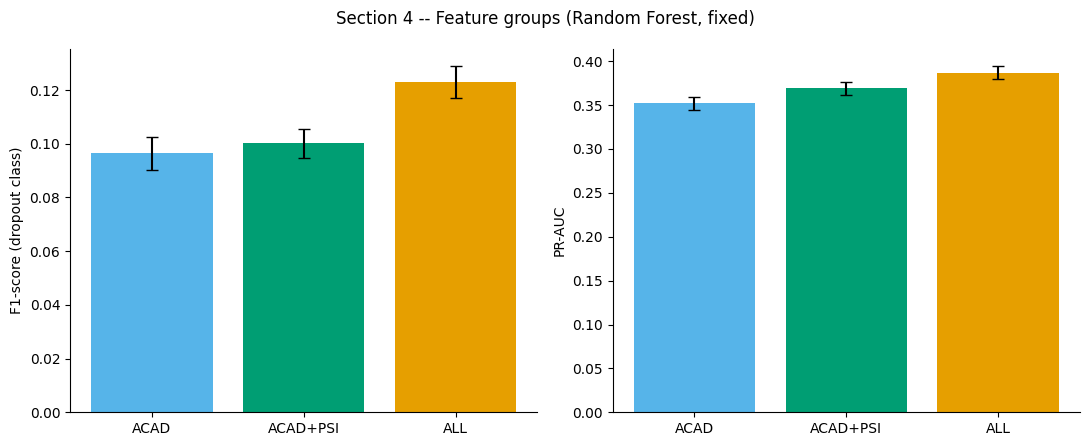

In [ ]:
resumen4 = (res4.groupby("brazo")[["f1_pos", "precision_pos", "recall_pos",
                                    "pr_auc", "roc_auc"]]
            .agg(["mean", "std"]).reindex(ARMS_4.keys()))
print(resumen4.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, met, lbl in zip(axes, ["f1_pos", "pr_auc"],
                        ["F1-score (dropout class)", "PR-AUC"]):
    m = res4.groupby("brazo")[met].mean().reindex(ARMS_4.keys())
    e = res4.groupby("brazo")[met].sem().reindex(ARMS_4.keys()) * 1.96
    ax.bar(range(len(m)), m.values, yerr=e.values, capsize=4,
           color=["#56B4E9", "#009E73", "#E69F00"])
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.index)
    ax.set_ylabel(lbl); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Section 4 -- Feature groups (Random Forest, fixed)")
fig.tight_layout()
fig.savefig(FIGS + "FINAL_04_feature_groups.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
def wilcoxon_holm(df_long, referencia, metrica):
    piv = df_long.pivot_table(index=["repeat", "fold"], columns="brazo", values=metrica)
    base = piv[referencia]
    filas = []
    for arm in piv.columns:
        if arm == referencia:
            continue
        w, p = stats.wilcoxon(piv[arm], base)
        filas.append(dict(brazo=arm, metrica=metrica,
                          dif_media=float((piv[arm] - base).mean()),
                          wilcoxon_p=float(p)))
    out = pd.DataFrame(filas)
    if len(out):
        m = len(out)
        order = out.wilcoxon_p.argsort()
        p_holm = np.empty(m); prev = 0.0
        for i, j in enumerate(order):
            prev = max(prev, min(1.0, (m - i) * out.wilcoxon_p.iloc[j]))
            p_holm[j] = prev
        out["p_holm"] = p_holm
    return out

test_f1_4 = wilcoxon_holm(res4, "ACAD", "f1_pos")
test_pr_4 = wilcoxon_holm(res4, "ACAD", "pr_auc")
print("F1 vs ACAD (Wilcoxon, Holm-corrected):\n", test_f1_4.round(4), "\n")
print("PR-AUC vs ACAD (Wilcoxon, Holm-corrected):\n", test_pr_4.round(4))


F1 vs ACAD (Wilcoxon, Holm-corrected):
       brazo metrica  dif_media  wilcoxon_p  p_holm
0  ACAD+PSI  f1_pos     0.0037      0.5245  0.5245
1       ALL  f1_pos     0.0266      0.0001  0.0002 

PR-AUC vs ACAD (Wilcoxon, Holm-corrected):
       brazo metrica  dif_media  wilcoxon_p  p_holm
0  ACAD+PSI  pr_auc     0.0173      0.0001  0.0001
1       ALL  pr_auc     0.0348      0.0001  0.0001


## 5. Balancing methods: Oversampling vs. Undersampling vs. Cost-Sensitive

Feature set fixed to the **winner of Section 4 by PR-AUC** (chosen the same
pre-registered way as the full ablation: PR-AUC rather than F1@0.5). Random Forest remains the
only classifier. Four arms, matching the reviewer's own list verbatim:

- **No Balancing**
- **Oversampling** (SMOTE-NC, in-fold)
- **Undersampling** (random, in-fold)
- **Cost-Sensitive** (`class_weight='balanced'`)


In [ ]:
ganador4 = res4.groupby("brazo")["pr_auc"].mean().idxmax()
print(f"Winner of Section 4 by mean PR-AUC: {ganador4}")
cols5 = columnas(ARMS_4[ganador4])

ARMS_5 = {"SIN_BALANCEO": "SIN_BALANCEO", "OVERSAMPLING": "OVERSAMPLING",
          "UNDERSAMPLING": "UNDERSAMPLING", "COSTO": "COSTO"}

filas = []
t0 = time.time()
for arm, balanceo in ARMS_5.items():
    for r, f, tr, te in FOLDS:
        pipe = hacer_pipeline(cols5, balanceo)
        pipe.fit(X.iloc[tr][cols5], y[tr])
        proba = pipe.predict_proba(X.iloc[te][cols5])[:, 1]
        m = metricas(y[te], proba)
        filas.append(dict(experimento="balancing", brazo=arm, feature_set=ganador4,
                          repeat=r, fold=f, **m))
    print(f"  {arm:14} done  ({time.time()-t0:5.1f}s elapsed)")

res5 = pd.DataFrame(filas)
res5.to_csv(RES + "final_ablation_results.csv", mode="a", index=False, header=False)
print(f"\nSection 5 finished in {time.time()-t0:.0f}s -- {len(res5)} rows")


Winner of Section 4 by mean PR-AUC: ALL


  SIN_BALANCEO   done  ( 40.6s elapsed)


  OVERSAMPLING   done  (233.6s elapsed)


  UNDERSAMPLING  done  (251.1s elapsed)


  COSTO          done  (286.8s elapsed)

Section 5 finished in 287s -- 60 rows


Balancing arms evaluated on the Section-4 winner (ALL):

                f1_pos         precision_pos         recall_pos          \
                  mean     std          mean     std       mean     std   
No Balancing    0.1230  0.0116        0.6032  0.0429     0.0685  0.0068   
Oversampling    0.3540  0.0116        0.4093  0.0182     0.3121  0.0101   
Undersampling   0.4139  0.0149        0.3189  0.0138     0.5902  0.0203   
Cost-Sensitive  0.4219  0.0173        0.3672  0.0175     0.4961  0.0202   

                pr_auc         roc_auc          
                  mean     std    mean     std  
No Balancing    0.3869  0.0143  0.7160  0.0103  
Oversampling    0.3546  0.0133  0.6993  0.0112  
Undersampling   0.3766  0.0133  0.7112  0.0111  
Cost-Sensitive  0.3846  0.0120  0.7140  0.0103  


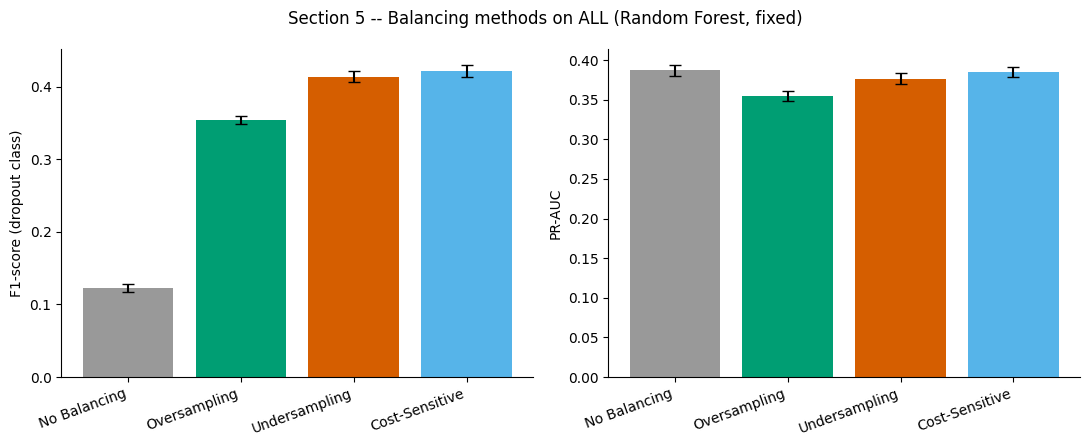

In [ ]:
ARM_LABEL_5 = {"SIN_BALANCEO": "No Balancing", "OVERSAMPLING": "Oversampling",
               "UNDERSAMPLING": "Undersampling", "COSTO": "Cost-Sensitive"}
orden5 = list(ARMS_5.keys())

resumen5 = (res5.groupby("brazo")[["f1_pos", "precision_pos", "recall_pos",
                                    "pr_auc", "roc_auc"]]
            .agg(["mean", "std"]).reindex(orden5))
resumen5.index = [ARM_LABEL_5[i] for i in resumen5.index]
print(f"Balancing arms evaluated on the Section-4 winner ({ganador4}):\n")
print(resumen5.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, met, lbl in zip(axes, ["f1_pos", "pr_auc"],
                        ["F1-score (dropout class)", "PR-AUC"]):
    m = res5.groupby("brazo")[met].mean().reindex(orden5)
    e = res5.groupby("brazo")[met].sem().reindex(orden5) * 1.96
    ax.bar(range(len(m)), m.values, yerr=e.values, capsize=4,
           color=["#999999", "#009E73", "#D55E00", "#56B4E9"])
    ax.set_xticks(range(len(m)))
    ax.set_xticklabels([ARM_LABEL_5[i] for i in m.index], rotation=20, ha="right")
    ax.set_ylabel(lbl); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Section 5 -- Balancing methods on {ganador4} (Random Forest, fixed)")
fig.tight_layout()
fig.savefig(FIGS + "FINAL_05_balancing.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
test_f1_5 = wilcoxon_holm(res5, "SIN_BALANCEO", "f1_pos")
test_pr_5 = wilcoxon_holm(res5, "SIN_BALANCEO", "pr_auc")
print("F1 vs No Balancing (Wilcoxon, Holm-corrected):\n", test_f1_5.round(4), "\n")
print("PR-AUC vs No Balancing (Wilcoxon, Holm-corrected):\n", test_pr_5.round(4))


F1 vs No Balancing (Wilcoxon, Holm-corrected):
            brazo metrica  dif_media  wilcoxon_p  p_holm
0          COSTO  f1_pos     0.2989      0.0001  0.0002
1   OVERSAMPLING  f1_pos     0.2310      0.0001  0.0002
2  UNDERSAMPLING  f1_pos     0.2910      0.0001  0.0002 

PR-AUC vs No Balancing (Wilcoxon, Holm-corrected):
            brazo metrica  dif_media  wilcoxon_p  p_holm
0          COSTO  pr_auc    -0.0023      0.0730  0.0730
1   OVERSAMPLING  pr_auc    -0.0324      0.0001  0.0002
2  UNDERSAMPLING  pr_auc    -0.0103      0.0001  0.0002
